Shape: (891, 12)
   survived  pclass     sex   age  sibsp  parch     fare embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S 

Missing values:
 age         177
cabin       687
embarked      2
dtype: int64 

Median Age: 28.0
Mode of Embarked: S
Sex encoding: {'female': 0, 'male': 1}

Missing values after cleaning: 0
Final shape: (891, 10)
Mean of scaled cols: {'age': 0.0, 'sibsp': 0.0, 'parch': 0.0, 'fare': 0.0}
Std of scaled cols: {'age': 1.0, 'sibsp': 1.0, 'parch': 1.0, 'fare': 1.0}

Clean, model-ready dataset:
    survived  pclass  sex     age   sibsp   parch    fare  embarked_C  \
0         0       3    1 -0.5657  0.4328 -0.4737 -0.5024           0   
1         1       1    0  0.6639  0.4328 -0.4737 

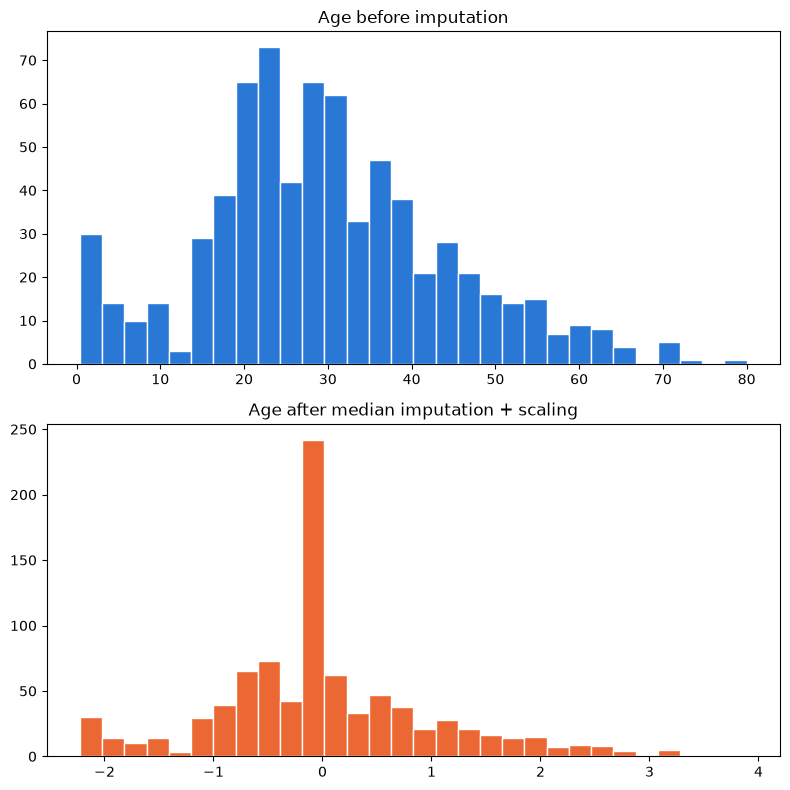


Cleaned dataset saved successfully!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Load dataset from local folder (OFFLINE)
df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.lower()

print("Shape:", df.shape)

print(df[["survived", "pclass", "sex", "age",
          "sibsp", "parch", "fare", "embarked"]].head(), "\n")


# 2. Check missing values
print("Missing values:\n",
      df.isnull().sum()[df.isnull().sum() > 0], "\n")

data = df[["survived", "pclass", "sex", "age",
           "sibsp", "parch", "fare", "embarked"]].copy()

age_before = data["age"].copy()


# 3. Missing numerical values: Median (Age)
print("Median Age:", data["age"].median())

data["age"] = data["age"].fillna(data["age"].median())


# 4. Missing categorical values: Mode (Embarked)
print("Mode of Embarked:", data["embarked"].mode()[0])

data["embarked"] = data["embarked"].fillna(
    data["embarked"].mode()[0]
)


# 5. Encoding: Label Encoding (Sex), One-Hot Encoding (Embarked)
le = LabelEncoder()

data["sex"] = le.fit_transform(data["sex"])

print("Sex encoding:", {
    c: int(v) for c, v in
    zip(le.classes_, le.transform(le.classes_))
})

data = pd.get_dummies(data, columns=["embarked"], dtype=int)


# 6. Scaling: StandardScaler
num_cols = ["age", "sibsp", "parch", "fare"]

data[num_cols] = StandardScaler().fit_transform(data[num_cols])


# 7. Verify transformed dataset
print("\nMissing values after cleaning:",
      int(data.isnull().sum().sum()))

print("Final shape:", data.shape)

print("Mean of scaled cols:",
      data[num_cols].mean().round(4).to_dict())

print("Std of scaled cols:",
      data[num_cols].std(ddof=0).round(4).to_dict())

print("\nClean, model-ready dataset:\n",
      data.head().round(4))


# 8. Visualize Age before and after preprocessing
fig, ax = plt.subplots(2, 1, figsize=(8, 8))

ax[0].hist(age_before.dropna(), bins=30,
           color="#2a78d6", edgecolor="white")
ax[0].set_title("Age before imputation")

ax[1].hist(data["age"], bins=30,
           color="#eb6834", edgecolor="white")
ax[1].set_title("Age after median imputation + scaling")

plt.tight_layout()
plt.show()


# 9. Save cleaned dataset
data.to_csv("titanic_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully!")
